
**Data.** seqFISH+ mouse NIH/3T3 fibroblasts (Eng et al., *Nature* 2019), batch 3: one field of view with 14 cells, held out as the test set of the SVC benchmark.

**Raw transcripts → spatial registration → gene-specific spatial representations → masked prediction with SVC → observed vs. predicted localization**

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

SVC_ROOT = Path(os.environ.get('SVC_ROOT', '..'))   # github.com/aster-ww/SVC
sys.path.insert(0, str(SVC_ROOT))
import plotting

DATA_ROOT = Path(os.environ.get('SVC_DATA_ROOT', '../data'))
DATA_DIR = DATA_ROOT / 'seqfish'
CKPT_DIR = Path('../checkpoints')
OUT_DIR = Path('../output/demo')
OUT_DIR.mkdir(parents=True, exist_ok=True)
plotting.setup()

CELL = "9-3"
GENES = ["Nid1", "Hnrnpf"]

## 1 · Raw subcellular transcript data

Each row is one detected mRNA molecule.

In [2]:
test = np.load(DATA_DIR / 'test_seqfish.npz', allow_pickle=True)
cells = list(test['cell_names'])
tx = pd.read_pickle(DATA_DIR / 'seqfish_data_dict.pkl')['data_df']
tx = tx[tx.cell.isin(cells)]
boundaries = pd.read_pickle(DATA_DIR / 'cell_mask_contour_preprocessed.pkl')
boundaries = boundaries[boundaries.cell.isin(cells)]
nuclei = pd.read_pickle(DATA_DIR / 'nuclear_mask_contour_preprocessed.pkl')
nuclei = nuclei[nuclei.cell.isin(cells)]

per_pair = tx.groupby(["cell", "gene"], observed=True).size()
print(f"{len(tx):,} molecules, {tx.cell.nunique()} cells, {tx.gene.nunique():,} genes, "
      f"median {per_pair.median():.0f} molecules per detected gene in a cell")
tx[["gene", "cell", "x", "y"]].sample(5, random_state=0)

342,829 molecules, 14 cells, 4,585 genes, median 8 molecules per detected gene in a cell


,gene,cell,x,y
1379952,Qsox1,8-3,1701.624442,934.167827
1404121,Zmpste24,12-3,586.928433,1164.450057
1259466,Nasp,3-3,528.424206,370.016147
1390188,Eif3l,12-3,607.376451,1383.295066
1317009,Mars,9-3,1561.746112,776.650701


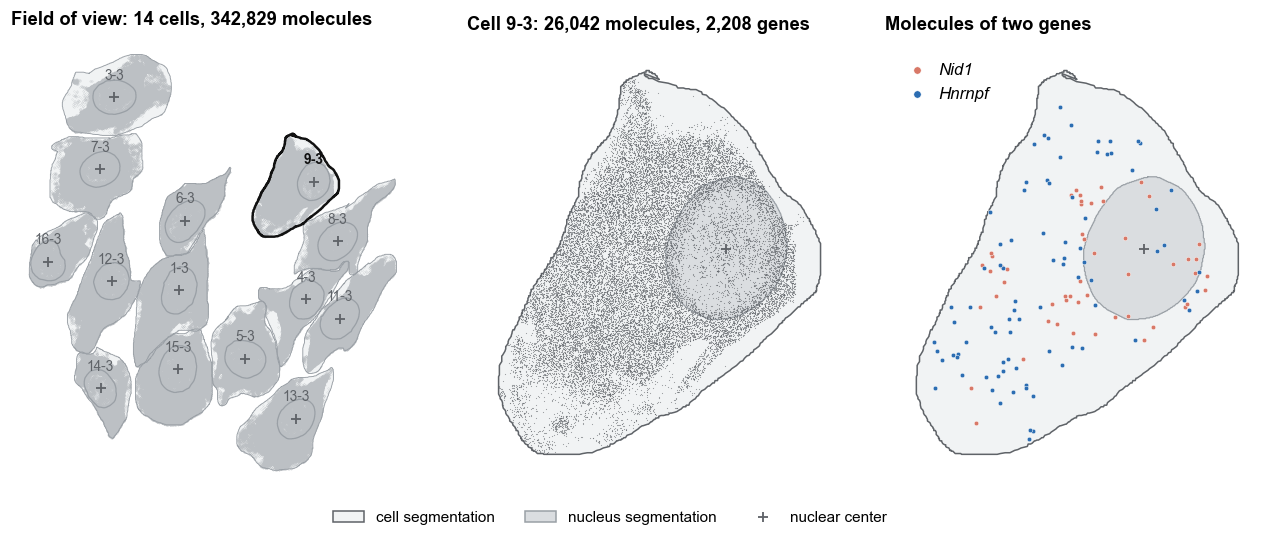

In [3]:
fig = plotting.raw_data(tx, boundaries, nuclei, CELL, GENES)

## 2 · Spatial registration

SVC first applies a cell registration procedure based on ELLA (Wang & Zhou, *Nature Communications* 2025) to establish a unified cellular coordinate system.
For each transcript, two spatial parameters are computed in polar coordinates: the angle θ, measured relative to the positive x-axis with the nuclear center as the origin, and the relative position

$$\rho = \frac{l_1}{l_1 + l_2},$$

where $l_1$ is its distance to the nuclear center and $l_2$ is its distance to the cell boundary in the opposite direction from the nuclear center.
Coordinate transformations that preserve θ and ρ project all transcripts within a cell onto a unit circle centered at the nuclear origin.

In the table, `ratio` is ρ, `direction_vec` is θ in degrees, and (`x_norm`, `y_norm`) = ρ (cos θ, sin θ).

In [4]:
from svc.register import register_transcripts

registered = register_transcripts(tx, boundaries)
example = registered[(registered.cell == CELL) & registered.gene.isin(GENES)]
example[["gene", "cell", "x", "y", "ratio", "direction_vec", "x_norm", "y_norm"]].head(4)

,gene,cell,x,y,ratio,direction_vec,x_norm,y_norm
1306779,Hnrnpf,9-3,1497.396482,812.398855,0.627715,137.0,-0.459081,0.428100
1306780,Hnrnpf,9-3,1684.394150,657.395023,0.225225,-10.5,0.221454,-0.041044
1306781,Hnrnpf,9-3,1439.644909,735.399693,0.853134,161.5,-0.809048,0.270704
1306782,Hnrnpf,9-3,1510.892246,577.897969,0.828063,-150.5,-0.720709,-0.407758


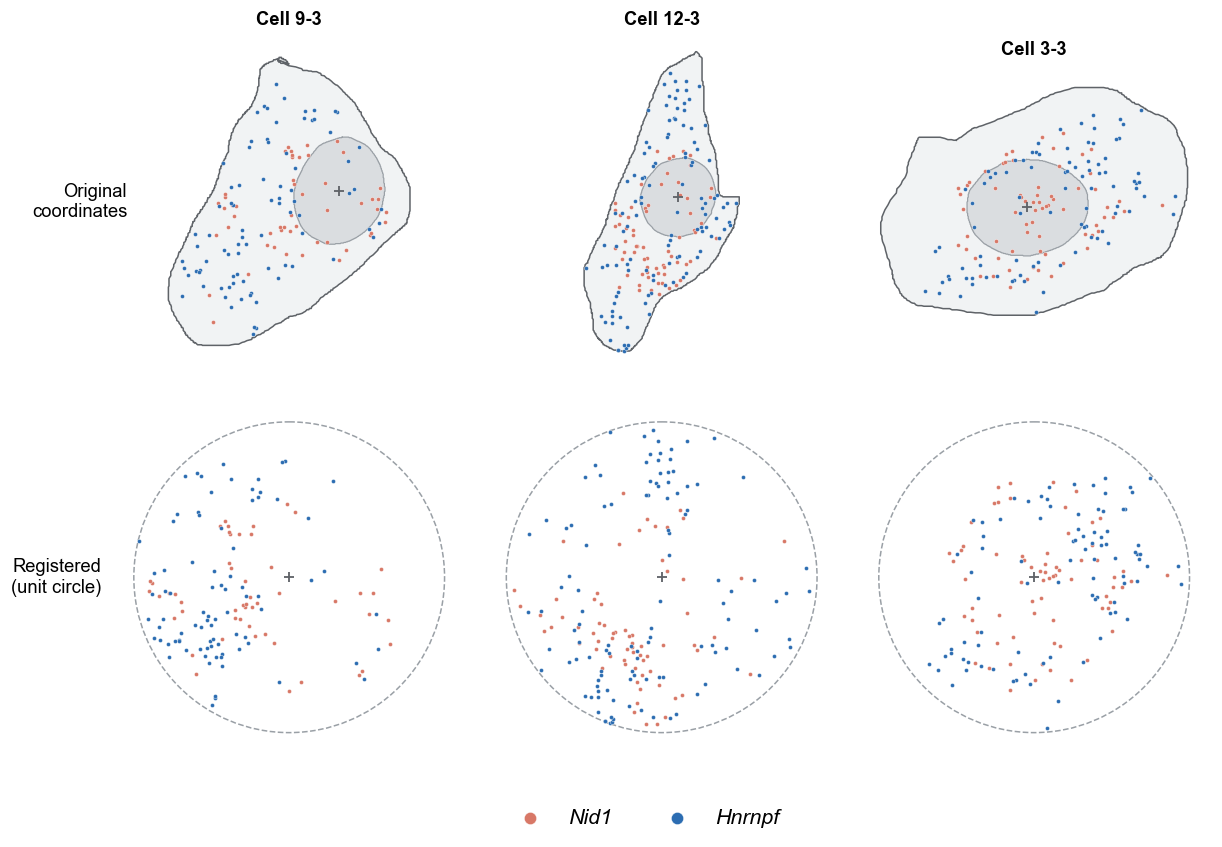

In [5]:
fig = plotting.registration(registered, boundaries, nuclei, ["9-3", "12-3", "3-3"], GENES)

## 3 · Gene-specific spatial representations

In the registered frame, the molecules of one gene in one cell are counted on a 48 × 48 grid, and 4 × 4 sum pooling turns the grid into a 12 × 12 map.

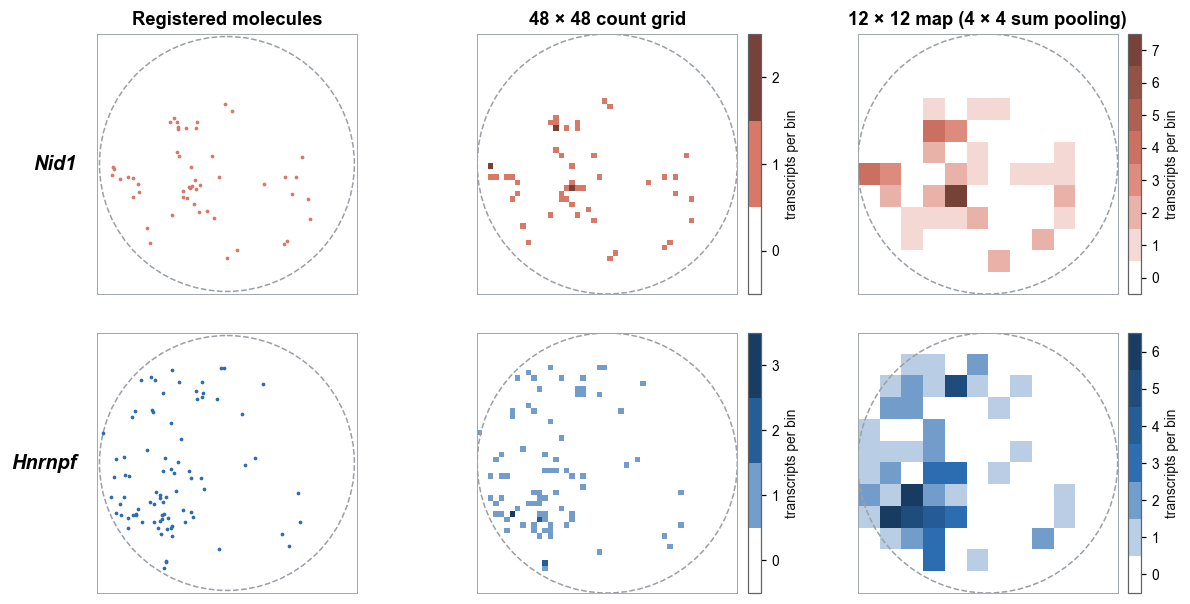

In [6]:
from svc.register import gene_maps

genes = np.loadtxt(DATA_DIR / 'gene_names.txt', dtype=str).tolist()

maps12 = gene_maps(registered, cells, genes)
maps48 = gene_maps(registered[registered.cell == CELL], [CELL], GENES, pool=1)[0]
example12 = maps12[cells.index(CELL), [genes.index(g) for g in GENES]]

fig = plotting.representations(registered, maps48, example12, CELL, GENES)

In [7]:
from svc.losses import BACKGROUND_PIXELS

in_panel = registered.gene.isin(genes)
rows, cols = np.array(BACKGROUND_PIXELS).T

checks = {
    f"12 × 12 maps for {len(cells)} cells × {len(genes):,} genes":
        maps12.shape == (len(cells), len(genes), 12, 12),
    "4 × 4 sum pooling of the 48 × 48 grid equals the 12 × 12 map":
        np.array_equal(maps48.reshape(len(GENES), 12, 4, 12, 4).sum(axis=(2, 4)), example12),
    f"all {in_panel.sum():,} panel molecules counted":
        maps12.sum() == in_panel.sum(),
    "no counts outside the unit circle":
        maps12[:, :, rows, cols].sum() == 0,
    "identical to the model inputs in test_seqfish.npz":
        np.array_equal(maps12, test['data_ori']),
}
for name, ok in checks.items():
    print("✓" if ok else "✗", name)
assert all(checks.values())

✓ 12 × 12 maps for 14 cells × 1,000 genes
✓ 4 × 4 sum pooling of the 48 × 48 grid equals the 12 × 12 map
✓ all 223,443 panel molecules counted
✓ no counts outside the unit circle
✓ identical to the model inputs in test_seqfish.npz


## 4 · Masked gene prediction with SVC

We randomly partition the 1,000 genes into 20 groups and perform 20-fold masked gene prediction.
In each fold, we mask one group of genes in the test cells and use the trained SVC model to predict their subcellular expression maps based on the remaining genes, together with the gene- and cell-level contexts.
Repeating this over the 20 groups gives predictions for all 1,000 genes.

In [8]:
!"{sys.executable}" {SVC_ROOT}/seqfish/evaluate.py --data-root {DATA_ROOT} --ckpt-dir {CKPT_DIR} --save-predictions > {OUT_DIR}/evaluate.log

## 5 · Observed vs. predicted RNA localization

For every masked gene and every pixel of the 12 × 12 map, SVC outputs a negative binomial (NB) distribution with mean $\hat\mu$ and inverse dispersion $\hat\varphi$.

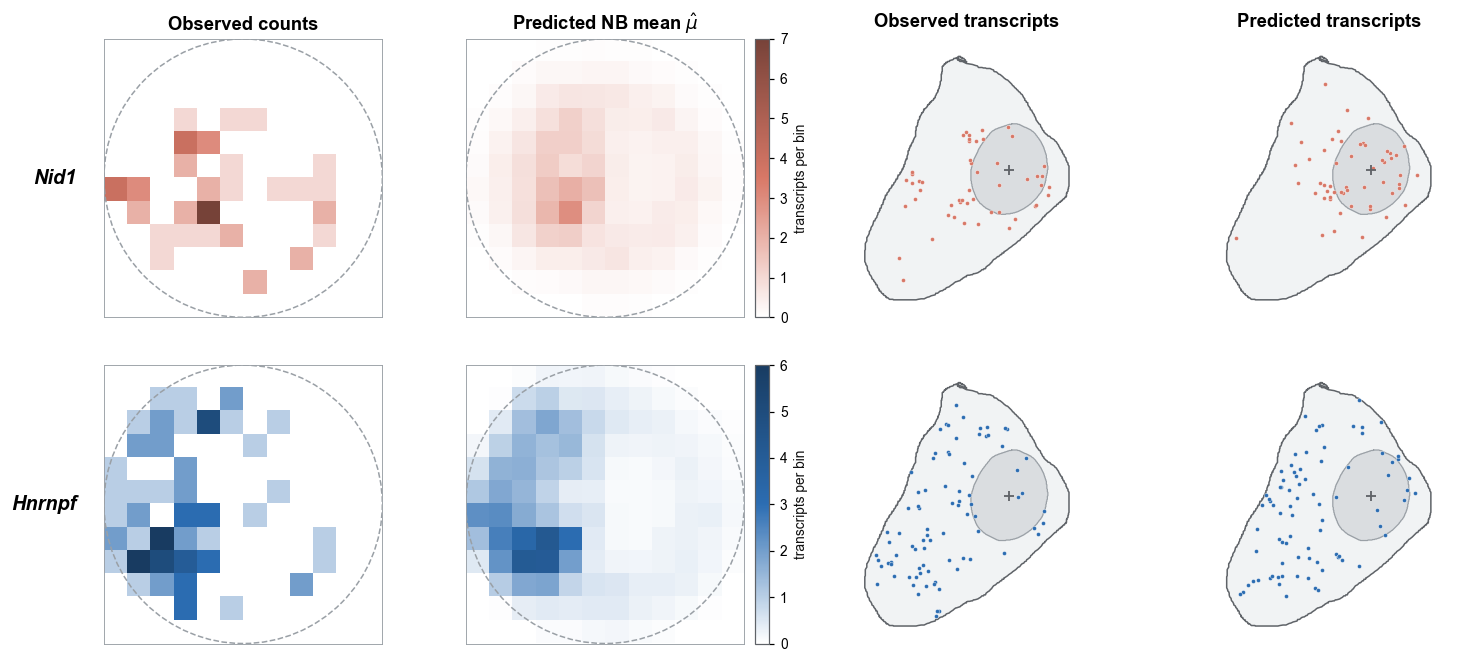

In [9]:
from svc.postprocess import expand_transcripts

os.environ["TQDM_DISABLE"] = "1"
!"{sys.executable}" {SVC_ROOT}/seqfish/postprocess.py --data-root {DATA_ROOT} --pred-dir {CKPT_DIR} --out {OUT_DIR}/predicted_transcripts.csv --genes {' '.join(GENES)} --seed {plotting.SEED} > {OUT_DIR}/postprocess.log
sampled = expand_transcripts(pd.read_csv(OUT_DIR / 'predicted_transcripts.csv'), jitter=True, seed=plotting.SEED)
mu = np.load(CKPT_DIR / 'prediction_mu.npz')['prediction']

fig = plotting.observed_vs_predicted(CELL, GENES, cells, genes, test['data_ori'], mu, tx, sampled,
                                     boundaries, nuclei)